# Auditoría conformal bajo cambio de covariables

## Resumen
Con n=80, el método ponderado correcto alcanza 94,717% de cobertura marginal frente a 51,616% sin ponderar. Pero 26,3255% de intervalos son infinitos: cobertura no equivale a utilidad. Con cambio condicional la cobertura cae a 79,619%. Simulación sintética; no evidencia operacional.

## Lectura de los resultados ejecutados

Se separaron cobertura total, intervalos finitos y cobertura útil; eliminar la masa de test cambia el método.

Resultados académicos adicionales (valores del experimento):

```json
{
  "CQR": [
    {
      "method": "simetrico",
      "region": "todos",
      "n": 3000,
      "coverage": 0.8986666666666666,
      "mean_width": 3.260944159419877
    },
    {
      "method": "CQR_positive",
      "region": "todos",
      "n": 3000,
      "coverage": 0.9,
      "mean_width": 2.872389233448361
    }
  ]
}
```

Datos sintéticos. Esta sección acompaña las salidas guardadas y no es una medición comercial o bancaria.

## Contexto y métodos

### Supuestos clave
Predictor $\hat\mu(x)=0$ fijado antes de calibración. $X\sim Bernoulli(0.1)$ en calibración y $Bernoulli(0.8)$ en destino. $Y|X\sim N(0,\sigma_X^2)$, $\sigma_0=1$, $\sigma_1=4$. Pesos $w(x)=q(x)/p(x)$ conocidos. Score $s_i=|y_i|$.

Umbral correcto:
$$q(x)=Q_{1-\alpha}\left(\sum_i \frac{w_i}{\sum_jw_j+w(x)}\delta_{s_i}+\frac{w(x)}{\sum_jw_j+w(x)}\delta_{+\infty}\right).$$
El baseline ingenuo omite la masa test; el baseline sin ponderar usa pesos uno y corrección finita. La garantía es marginal, no por grupo. El aporte es auditoría reproducible, no un algoritmo nuevo. Fuentes en `referencias.bib`, especialmente Tibshirani et al. (2019).

## Datos y configuración
Datos sintéticos independientes; 100 calibraciones por escenario, 2.000 puntos de prueba por calibración. Métodos pareados. Semilla fija; error Monte Carlo se calcula entre calibraciones, no tratando 200.000 puntos como independientes.

In [1]:
import json
from pathlib import Path
from IPython.display import display, Image
r = json.loads(Path("results/summary.json").read_text())
r["config"]

Out[1]: 
{'seed': 20261023,
 'alpha': 0.1,
 'source_high': 0.1,
 'target_high': 0.8,
 'calibration_sizes': [40, 80, 320],
 'test_size': 2000,
 'repeats': 100,
 'predictor': 'fixed oracle conditional mean zero',
 'dataset': 'synthetic Bernoulli covariate, heteroskedastic Gaussian residual; no private data',
 'hypothesis': 'correct_weighted coverage >=0.88 and improves >=0.10 over unweighted at n=80 under covariate_shift'}


## Resultados
La tabla permite auditar cobertura marginal, cobertura del grupo de ruido alto, proporción finita y ancho entre intervalos finitos. Si existe cualquier intervalo infinito, el ancho medio incondicional es infinito: no se debe interpretar el ancho finito como coste total.

In [2]:
for row in r["summary"]:
    if row["n"] == 80:
        print(row["scenario"], row["method"], "coverage=", round(row["coverage"], 5), "finite_rate=", round(row["finite_rate"], 5), "finite_width=", round(row["finite_mean_width"], 3))

no_shift unweighted coverage= 0.8999 finite_rate= 1.0 finite_width= 4.292
no_shift naive_weighted coverage= 0.88627 finite_rate= 1.0 finite_width= 3.995
no_shift correct_weighted coverage= 0.8999 finite_rate= 1.0 finite_width= 4.292
covariate_shift unweighted coverage= 0.51616 finite_rate= 1.0 finite_width= 4.292
covariate_shift naive_weighted coverage= 0.86267 finite_rate= 1.0 finite_width= 12.031
covariate_shift correct_weighted coverage= 0.94717 finite_rate= 0.73674 finite_width= 13.808
conditional_shift unweighted coverage= 0.31094 finite_rate= 1.0 finite_width= 4.292
conditional_shift naive_weighted coverage= 0.62312 finite_rate= 1.0 finite_width= 12.031
conditional_shift correct_weighted coverage= 0.79619 finite_rate= 0.73674 finite_width= 13.808


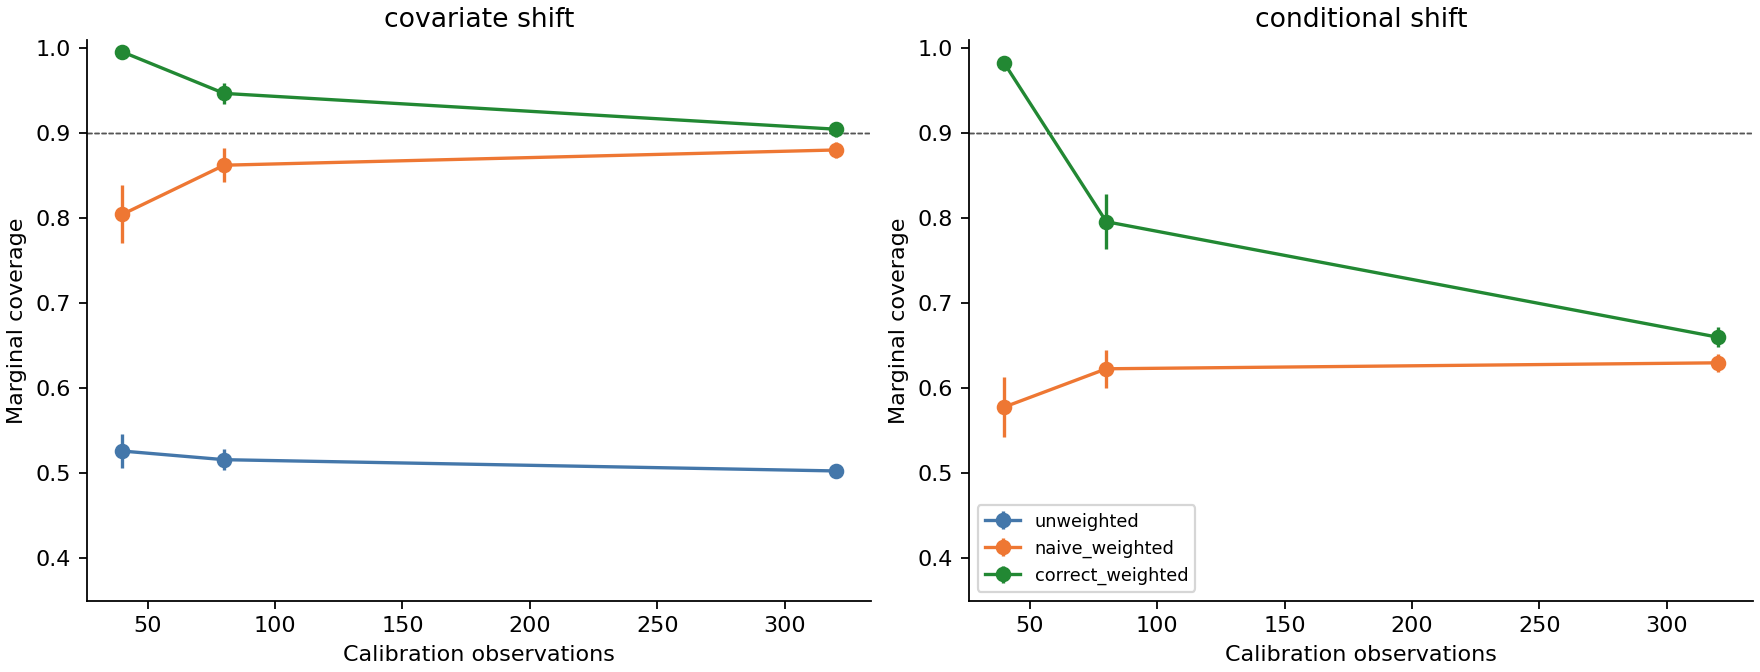

In [3]:
display(Image(filename="results/coverage.png"))

### Lectura de la figura
Las barras son ±1,96 errores estándar Monte Carlo entre 100 réplicas; no son garantía matemática ni intervalos simultáneos. El método correcto resulta conservador con n=40 porque devuelve muchos intervalos infinitos. Al aumentar n, mejora la utilidad pero se revela el fallo ante cambio condicional.

In [4]:
rows = r["summary"]
def row(scenario, method, n=80):
    return next(x for x in rows if x["scenario"] == scenario and x["method"] == method and x["n"] == n)
correct = row("covariate_shift", "correct_weighted")
baseline = row("covariate_shift", "unweighted")
assert correct["coverage"] >= .88
assert correct["coverage"] - baseline["coverage"] >= .10
assert row("conditional_shift", "correct_weighted")["coverage"] < .88
assert correct["finite_rate"] < 1
print("Hipótesis sintética confirmada; falsificación condicional e inutilidad parcial detectadas.")
r["execution"]

Hipótesis sintética confirmada; falsificación condicional e inutilidad parcial detectadas.
Out[4]: 
{'seconds': 1.0765255250000791,
 'python_peak_bytes': 1989503,
 'process_maxrss_kib': 56660,
 'python': '3.12.14',
 'numpy': '2.3.5',
 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39',
 'processor': 'x86_64',
 'cpu_count': 9,
 'notes': 'tracemalloc tracks Python allocations; RSS is whole-process peak, not method-specific'}


## Conclusiones y límites
La masa test evita presentar cuantiles finitos injustificados cuando el solapamiento es débil. No basta para obtener cobertura por grupo ni robustez a cambios de Y|X. Los pesos son oráculo; no se evaluó estimación de ratios, datos reales ni operación. El siguiente experimento debe incorporar pesos estimados con muestra no etiquetada independiente y una regla explícita de derivación humana cuando el intervalo sea infinito.

## Laboratorio ampliado — derivación, usos y refutación

Experimentos adicionales del 23 de octubre de 2026. Datos sintéticos; las cifras guardadas del estudio original se conservan y las nuevas se recalculan debajo.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize':(8,4.6),'font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
BLUE='#245B83'; GOLD='#B57A21'; GRAY='#4D5358'
rng_depth=np.random.default_rng(20261023)

### Conformal ponderado y masa del nuevo punto

Con scores de calibración $s_i$ y razones de densidad $w_i=dQ_X/dP_X(x_i)$:

$$q(x)=Q_{1-\alpha}\left(\sum_i\frac{w_i\delta_{s_i}}{\sum_jw_j+w(x)}+\frac{w(x)\delta_{+\infty}}{\sum_jw_j+w(x)}\right).$$

La masa de test no se elimina. Si $(1-\alpha)(\sum w_i+w(x))>\sum w_i$, el intervalo es infinito. Predictor independiente, razones correctas, solapamiento y distribución $Y|X$ invariante son supuestos esenciales. Cobertura marginal no es cobertura por segmento.

### Cuantil como distribución discreta

Reconstrucción manual pequeña, incluyendo un nuevo punto de peso dominante.

In [6]:
from src.conformal import thresholds, ratios
scores_d=np.array([1.,2.,3.,4.]);weights_d=np.array([1.,1.,2.,2.])
test_weights_d=np.array([.1,2.,20.])
q_d=thresholds(scores_d,weights_d,test_weights_d,alpha=.2)
manual=[]
for wt in test_weights_d:
    target=.8*(weights_d.sum()+wt)
    choices=scores_d[np.cumsum(weights_d)>=target]
    manual.append(choices[0] if len(choices) else np.inf)
assert np.array_equal(q_d,manual)
display(pd.DataFrame({'peso_test':test_weights_d,'q':q_d}))

,peso_test,q
0,0.1,4.0
1,2.0,inf
2,20.0,inf


### Masa infinita y utilidad

El diagnóstico separa cobertura, fracción finita y ancho condicional a ser finito; no sustituir infinito por el mayor score.

Frontera analítica de finitud: 17.014746189298187


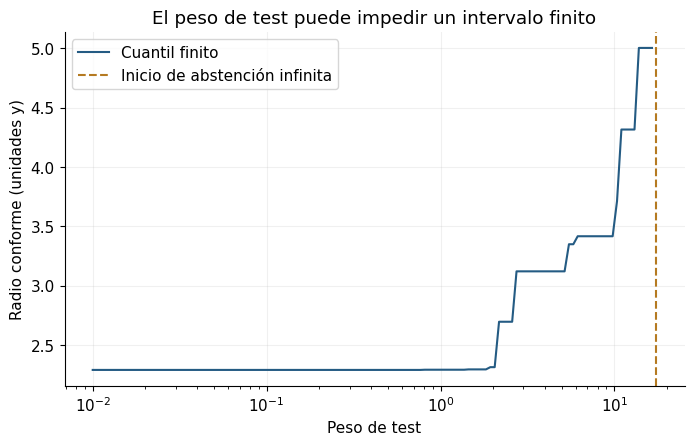

In [7]:
scores_d=np.sort(rng_depth.exponential(size=80))
weights_d=rng_depth.lognormal(0,1,size=80)
test_grid=np.geomspace(.01,1000,200)
quantiles_d=thresholds(scores_d,weights_d,test_grid)
fig,ax=plt.subplots();finite=np.isfinite(quantiles_d)
ax.plot(test_grid[finite],quantiles_d[finite],color=BLUE,label='Cuantil finito')
if (~finite).any(): ax.axvline(test_grid[~finite][0],color=GOLD,ls='--',label='Inicio de abstención infinita')
ax.set(xscale='log',xlabel='Peso de test',ylabel='Radio conforme (unidades y)',title='El peso de test puede impedir un intervalo finito');ax.legend();plt.show()
print('Frontera analítica de finitud:', .1/.9*weights_d.sum())

### Invariancia por escala común y ESS

ESS es un diagnóstico de concentración, no un certificado de cobertura. Escalar solo pesos de calibración cambia la política.

In [8]:
base=thresholds(scores_d,weights_d,test_grid)
scaled=thresholds(scores_d,weights_d*17,test_grid*17)
assert np.array_equal(base,scaled)
ess=weights_d.sum()**2/np.sum(weights_d**2)
print({'n_cal':len(weights_d),'ESS':ess,'fraccion_finita_grid':finite.mean()})

{'n_cal': 80, 'ESS': np.float64(35.58931405602078), 'fraccion_finita_grid': np.float64(0.645)}


### Ablación de pesos mal especificados

Datos nuevos con semilla fija; se perturba la razón oráculo sin ajustar etiquetas de test.

,target_asumido,cobertura,fraccion_finita,ancho_finito
0,0.10,0.4675,1.0,4.4805
1,0.30,0.6915,1.0,8.6995
2,0.50,0.7552,1.0,10.2913
3,0.80,0.8682,1.0,13.3531
4,0.95,0.9260,1.0,16.2755


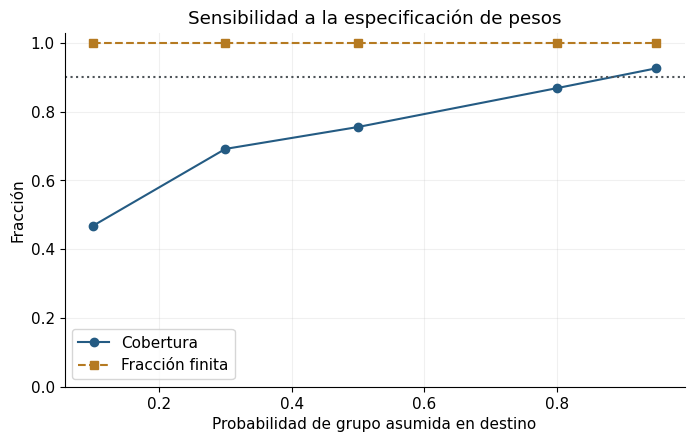

In [9]:
g_cal=rng_depth.random(400)<.1;g_test=rng_depth.random(4000)<.8
s_cal=np.abs(rng_depth.normal(size=400))*np.where(g_cal,5.,1.)
s_test=np.abs(rng_depth.normal(size=4000))*np.where(g_test,5.,1.)
weight_rows=[]
for target_assumed in [.1,.3,.5,.8,.95]:
    wc=ratios(g_cal,.1,target_assumed);wt=ratios(g_test,.1,target_assumed)
    q=thresholds(s_cal,wc,wt)
    is_finite=np.isfinite(q)
    weight_rows.append({'target_asumido':target_assumed,'cobertura':np.mean(s_test<=q),'fraccion_finita':is_finite.mean(),'ancho_finito':2*np.mean(q[is_finite]) if is_finite.any() else np.nan})
weight_table=pd.DataFrame(weight_rows);display(weight_table.round(4))
fig,ax=plt.subplots();ax.plot(weight_table.target_asumido,weight_table.cobertura,'o-',color=BLUE,label='Cobertura')
ax.plot(weight_table.target_asumido,weight_table.fraccion_finita,'s--',color=GOLD,label='Fracción finita');ax.axhline(.9,color=GRAY,ls=':')
ax.set(ylim=(0,1.03),xlabel='Probabilidad de grupo asumida en destino',ylabel='Fracción',title='Sensibilidad a la especificación de pesos');ax.legend();plt.show()

### Cambio condicional

Con los mismos pesos correctos, multiplicar los errores de destino rompe el supuesto de Y dado X invariante.

In [10]:
q_correct=thresholds(s_cal,ratios(g_cal,.1,.8),ratios(g_test,.1,.8))
conditional=pd.DataFrame({'factor_error':[1,1.5,2,3]})
conditional['cobertura']=[np.mean(s_test*factor<=q_correct) for factor in conditional.factor_error]
display(conditional)
assert conditional.cobertura.iloc[-1]<=conditional.cobertura.iloc[0]

,factor_error,cobertura
0,1.0,0.86825
1,1.5,0.70900
2,2.0,0.60100
3,3.0,0.46975


### Uso y arquitectura

Incorporar al monitoreo de modelos cuando las razones sean defendibles y el predictor esté congelado. Registrar cobertura y fracción útil juntas. Antes de conectar una API de decisión, evaluar densidad estimada, error de etiquetas, subgrupos y política de abstención. No transferir la garantía oráculo a pesos aprendidos sin análisis adicional.

### Preguntas para extender el estudio

1. ¿Qué supuesto permite el resultado y qué contraejemplo lo destruye?
2. ¿Qué cambia al separar entrenamiento, calibración y evaluación por fecha?
3. ¿Qué pérdidas, costos o acciones no están representados?
4. ¿Qué evidencia real haría abandonar este modelo?

Las salidas anteriores son el resultado de esta ejecución; las pruebas locales no establecen validez empírica.

### Pesos extremos y abstención útil

Se mide el límite de resolución sin clipping silencioso; una razón de densidad extrema es parte del problema de solapamiento.

In [11]:
concentration=[]
for sigma in [0,.5,1,2,3]:
    weights=np.exp(sigma*rng_depth.normal(size=200))
    test_w=np.exp(sigma*rng_depth.normal(size=1000))
    quantile=thresholds(np.abs(rng_depth.normal(size=200)),weights,test_w)
    concentration.append({'sigma_log_peso':sigma,'ESS':weights.sum()**2/np.sum(weights**2),'fraccion_infinita':np.mean(~np.isfinite(quantile))})
display(pd.DataFrame(concentration).round(4))

,sigma_log_peso,ESS,fraccion_infinita
0,0.0,200.0000,0.000
1,0.5,163.3838,0.000
2,1.0,88.0163,0.000
3,2.0,3.2367,0.001
4,3.0,4.3821,0.007


### Cobertura por subgrupo

Una garantía marginal no promete 90% en cada grupo. Los denominadores se muestran y los intervalos Wilson describen este test condicionado a calibración.

In [12]:
from scipy.stats import binomtest
subgroup=[]
for name,mask in [('grupo0',~g_test),('grupo1',g_test)]:
    covered=s_test[mask]<=q_correct[mask]
    interval=binomtest(int(covered.sum()),len(covered)).proportion_ci(method='wilson')
    subgroup.append({'grupo':name,'n':int(mask.sum()),'cobertura':covered.mean(),'lo':interval.low,'hi':interval.high,'fraccion_finita':np.isfinite(q_correct[mask]).mean()})
display(pd.DataFrame(subgroup).round(4))

,grupo,n,cobertura,lo,hi,fraccion_finita
0,grupo0,744,1.0000,0.9949,1.0000,1.0
1,grupo1,3256,0.8381,0.8251,0.8504,1.0


### Cobertura útil y cobertura total

Los infinitos cubren por construcción; reportar solo cobertura puede premiar abstenerse siempre. La cobertura entre finitos es descriptiva y no hereda la garantía marginal.

In [13]:
finite_mask=np.isfinite(q_correct)
covered=s_test<=q_correct
useful_covered=np.mean(covered & finite_mask)
finite_coverage=float(covered[finite_mask].mean()) if finite_mask.any() else None
print({'cobertura_total':covered.mean(),'fraccion_finita':finite_mask.mean(),'cobertura_entre_finitos':finite_coverage,'cobertura_util_sobre_todos':useful_covered})
assert useful_covered<=covered.mean()
assert useful_covered<=finite_mask.mean()

{'cobertura_total': np.float64(0.86825), 'fraccion_finita': np.float64(1.0), 'cobertura_entre_finitos': 0.86825, 'cobertura_util_sobre_todos': np.float64(0.86825)}


### Interpretación de las pruebas adicionales

Cada experimento modifica un supuesto concreto. Las comparaciones conservan denominadores, unidades y desconocidos; los resultados negativos forman parte de la evidencia. Las simulaciones no convierten un diseño en un sistema operativo ni sustituyen validación independiente con datos aprobados.

## Ampliación académica: literatura, fórmulas y experimento

Consulta bibliográfica del 23 de octubre de 2026. Se distingue método publicado, derivación propia y experimento sintético. El [mapa bibliográfico](https://github.com/Jose85100/Portafolio/blob/research/2026-10-23-multi-domain-cycle/reviews/2026-10-23-academic/README.md) en la raíz del repositorio registra publicaciones, acceso y brechas; las fuentes específicas se enlazan debajo.

### Conformalized Quantile Regression para anchos heterogéneos

[Romano, Patterson y Candès, NeurIPS 2019, §2](https://proceedings.neurips.cc/paper/2019/file/5103c3584b063c431bd1268e9b5e76fb-Paper.pdf). Con cuantiles entrenados fuera de calibración:

$$s_i=\max\{\widehat q_{lo}(x_i)-y_i,\ y_i-\widehat q_{hi}(x_i)\},$$
$$\widehat C(x)=[\widehat q_{lo}(x)-Q,\widehat q_{hi}(x)+Q],\quad k=\lceil(n+1)(1-\alpha)\rceil.$$

Aquí usamos $s_i^+=\max(0,s_i)$: variante conservadora que solo ensancha. No es la variante de shrinkage del artículo. El experimento es IID heterocedástico; no se le transfiere la garantía de covariate shift del laboratorio original.

### Entrenamiento, calibración y test separados

Se ajustan tres boosters en train: media y cuantiles 5%/95%. El test se usa exclusivamente para medir.

In [14]:
from sklearn.ensemble import GradientBoostingRegressor
paper_rng=np.random.default_rng(2304)
def hetero_data(n):
    x=paper_rng.uniform(-2,2,n)
    y=np.sin(x)+(.15+.7*np.abs(x))*paper_rng.normal(size=n)
    return x[:,None],y
X_train,Y_train=hetero_data(1500)
X_cal,Y_cal=hetero_data(600)
X_eval,Y_eval=hetero_data(3000)
models_paper={}
for name,loss,quantile in [('mean','squared_error',.5),('low','quantile',.05),('high','quantile',.95)]:
    model=GradientBoostingRegressor(loss=loss,alpha=quantile,n_estimators=80,max_depth=2,random_state=23)
    models_paper[name]=model.fit(X_train,Y_train)

def bands(x):
    low=models_paper['low'].predict(x);high=models_paper['high'].predict(x)
    return np.minimum(low,high),np.maximum(low,high)

low_c,high_c=bands(X_cal)
cqr_scores=np.maximum(0,np.maximum(low_c-Y_cal,Y_cal-high_c))
abs_scores=np.abs(Y_cal-models_paper['mean'].predict(X_cal))
k=int(np.ceil((len(Y_cal)+1)*.9))
q_cqr=np.partition(cqr_scores,k-1)[k-1]
q_abs=np.partition(abs_scores,k-1)[k-1]
lo_e,hi_e=bands(X_eval)
lo_e=lo_e-q_cqr;hi_e=hi_e+q_cqr
mean_e=models_paper['mean'].predict(X_eval)

### Cobertura y ancho por región

La cobertura marginal no equivale a cobertura en cada región. Se conserva el baseline simétrico y no se exige que CQR gane siempre.

ACADEMIC_METRICS:{"CQR": [{"method": "simetrico", "region": "todos", "n": 3000, "coverage": 0.8986666666666666, "mean_width": 3.260944159419877}, {"method": "CQR_positive", "region": "todos", "n": 3000, "coverage": 0.9, "mean_width": 2.872389233448361}]}


,method,region,n,coverage,mean_width
0,simetrico,todos,3000,0.8987,3.2609
1,simetrico,central,908,1.0000,3.2609
2,simetrico,extremo,923,0.7497,3.2609
3,CQR_positive,todos,3000,0.9000,2.8724
4,CQR_positive,central,908,0.9207,1.3852
5,CQR_positive,extremo,923,0.8559,4.1635


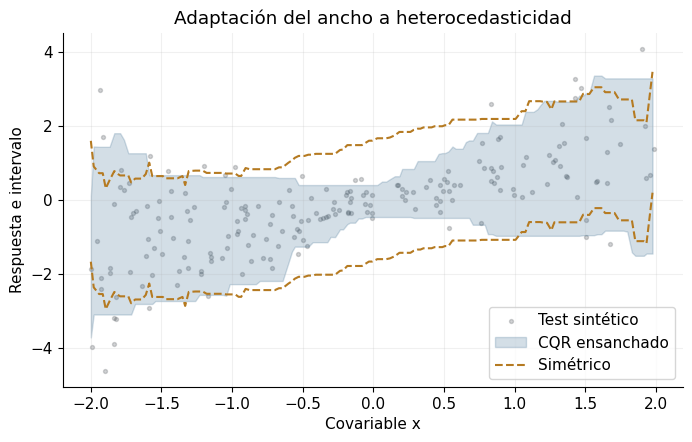

In [15]:
cqr_rows=[]
for name,lo,hi in [('simetrico',mean_e-q_abs,mean_e+q_abs),('CQR_positive',lo_e,hi_e)]:
    for region,mask in [('todos',np.ones(len(Y_eval),bool)),('central',np.abs(X_eval[:,0])<.6),('extremo',np.abs(X_eval[:,0])>1.4)]:
        cqr_rows.append({'method':name,'region':region,'n':int(mask.sum()),
                         'coverage':float(np.mean((Y_eval[mask]>=lo[mask])&(Y_eval[mask]<=hi[mask]))),
                         'mean_width':float(np.mean(hi[mask]-lo[mask]))})
cqr_table=pd.DataFrame(cqr_rows);display(cqr_table.round(4))
order=np.argsort(X_eval[:,0])[::20]
fig,ax=plt.subplots()
ax.scatter(X_eval[::15,0],Y_eval[::15],s=8,color=GRAY,alpha=.25,label='Test sintético')
ax.fill_between(X_eval[order,0],lo_e[order],hi_e[order],color=BLUE,alpha=.2,label='CQR ensanchado')
ax.plot(X_eval[order,0],mean_e[order]+q_abs,color=GOLD,ls='--',label='Simétrico')
ax.plot(X_eval[order,0],mean_e[order]-q_abs,color=GOLD,ls='--')
ax.set(xlabel='Covariable x',ylabel='Respuesta e intervalo',title='Adaptación del ancho a heterocedasticidad')
ax.legend();plt.show()
import json
print('ACADEMIC_METRICS:'+json.dumps({'CQR':cqr_table[cqr_table.region=='todos'].to_dict(orient='records')}))

### Próximas líneas: adaptación temporal

[Gibbs y Candès, NeurIPS 2021, ecuación 2](https://proceedings.neurips.cc/paper/2021/file/0d441de75945e5acbc865406fc9a2559-Paper.pdf): $\alpha_{t+1}=\alpha_t+\gamma(\alpha-err_t)$. La evaluación requiere observar la etiqueta después de predecir y distinguir frecuencia temporal de cobertura condicional. Su ampliación [JMLR 2024](https://jmlr.org/papers/v25/22-1218.html) adapta el paso. Se documentan como próximos experimentos; no se afirma haber implementado ACI.